# Diabetes status prediction: Logistic Regression and Random Forest
Run the cells **in order** in Google Colab (Runtime > Run all). This version corrects and extends the original notebook so that every number in the dissertation can be regenerated and checked.

**What changed from the original notebook**
1. Library versions are checked against the versions used for the reported run (scikit-learn 1.6.1, pandas 2.2.3, numpy 2.4.6) so that results match exactly.
2. The coefficient and importance cell of the original had no saved output, so Figures 8 and 9 were missing from the results ZIP. It is kept, and the final cell now refuses to build the ZIP unless every expected file exists.
3. Predicted probabilities are saved, so ROC-AUC confidence intervals and paired differences can be computed.
4. A new **report-matching section** exports every number used in the dissertation (specificity, NPV, confusion-matrix counts, bootstrap intervals, odds ratios, duplicate-profile overlap, break-even cost ratio) and checks the key results against the reported values with PASS or FAIL.

The positive class combines prediabetes and diabetes. The analysis does not predict future onset or complications. Dataset: Alex Teboul, Diabetes Health Indicators Dataset, BRFSS 2015, Kaggle.

**Use the three-class file `diabetes_012_health_indicators_BRFSS2015.csv`. The `diabetes_binary` file treats prediabetes as negative (35,346 positives) and will NOT reproduce the report.**

In [ ]:
%pip -q install kagglehub

In [1]:
from pathlib import Path
import json, platform, shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
SEED = 42
OUT = Path('/content/diabetes_results')
OUT.mkdir(exist_ok=True)
REPORTED_ENV = {'python': '3.13', 'sklearn': '1.6.1', 'pandas': '2.2.3', 'numpy': '2.4.6'}
current = {'python': platform.python_version(), 'sklearn': sklearn.__version__,
           'pandas': pd.__version__, 'numpy': np.__version__}
print('Current  :', current)
print('Reported :', REPORTED_ENV)
mismatch = {k: (current[k], v) for k, v in REPORTED_ENV.items() if not current[k].startswith(v)}
if mismatch:
    print('\nWARNING: library versions differ from the reported run:', mismatch)
    print('Exact agreement of the Random Forest results is not guaranteed.')
    print('To match exactly, run in a fresh runtime:  %pip install scikit-learn==1.6.1 pandas==2.2.3')
    print('then Runtime > Restart session, and run all cells.')

Current  : {'python': '3.13.18', 'sklearn': '1.6.1', 'pandas': '2.2.3', 'numpy': '2.4.6'}
Reported : {'python': '3.13', 'sklearn': '1.6.1', 'pandas': '2.2.3', 'numpy': '2.4.6'}


## 1. Obtain the correct dataset
The automatic option selects the full three-class CSV. If the Kaggle download fails, set `USE_MANUAL_UPLOAD = True`, rerun this cell and upload the extracted three-class CSV (not the ZIP).

In [2]:
USE_MANUAL_UPLOAD = False
if USE_MANUAL_UPLOAD:
    from google.colab import files
    uploaded = files.upload()
    choices = [Path(name) for name in uploaded if name.lower().endswith('.csv')]
    if len(choices) != 1:
        raise ValueError('Upload exactly one CSV: diabetes_012_health_indicators_BRFSS2015.csv')
    csv_path = choices[0]
else:
    import kagglehub
    folder = Path(kagglehub.dataset_download('alexteboul/diabetes-health-indicators-dataset'))
    choices = [p for p in folder.rglob('*.csv')
               if p.name.lower() == 'diabetes_012_health_indicators_brfss2015.csv']
    if len(choices) != 1:
        raise FileNotFoundError('Three-class CSV not found. Use the manual upload option.')
    csv_path = choices[0]
df = pd.read_csv(csv_path)
print('Loaded:', csv_path.name, 'Shape:', df.shape)
display(df.head())

Using Colab cache for faster access to the 'diabetes-health-indicators-dataset' dataset.
Loaded: diabetes_012_health_indicators_BRFSS2015.csv Shape: (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [5]:
features = ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke',
            'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
            'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
            'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
scaled = ['BMI', 'MentHlth', 'PhysHlth', 'Age', 'GenHlth', 'Education', 'Income']
required = features + ['Diabetes_012']
if not set(required).issubset(df.columns):
    raise ValueError('Wrong file or missing columns: ' + str(set(required) - set(df.columns)))
if len(df) != 253680:
    raise ValueError('Expected 253,680 rows. Check the dataset version before proceeding.')
if df[required].isna().any().any():
    raise ValueError('Missing values found. Investigate before running this report-specific pipeline.')
if not set(df['Diabetes_012'].unique()).issubset({0, 1, 2}):
    raise ValueError('Unexpected target values.')
X = df[features].copy()
y = df['Diabetes_012'].isin([1, 2]).astype(int).rename('Diabetes_binary')
quality = {'rows': len(df), 'features': len(features),
           'missing_cells': int(df[required].isna().sum().sum()),
           'duplicate_rows_original_columns': int(df[required].duplicated().sum()),
           'class_0_no_diabetes': int((df['Diabetes_012'] == 0).sum()),
           'class_1_prediabetes': int((df['Diabetes_012'] == 1).sum()),
           'class_2_diabetes': int((df['Diabetes_012'] == 2).sum())}
print(quality)
summary = y.value_counts().sort_index().rename('count').to_frame()
summary['percentage'] = summary['count'] / len(y) * 100
summary.index.name = 'Diabetes_binary'
display(summary)
summary.to_csv(OUT / 'class_distribution.csv')
df[required].describe().T.to_csv(OUT / 'descriptive_statistics.csv')
(OUT / 'data_quality.json').write_text(json.dumps(quality, indent=2))

{'rows': 253680, 'features': 21, 'missing_cells': 0, 'duplicate_rows_original_columns': 23899, 'class_0_no_diabetes': 213703, 'class_1_prediabetes': 4631, 'class_2_diabetes': 35346}


,count,percentage
Diabetes_binary,,
0,213703,84.24117
1,39977,15.75883


197

## 2. Exploratory analysis
Plots describe associations with the combined outcome, not causal effects. They are not used to select features or tune models.

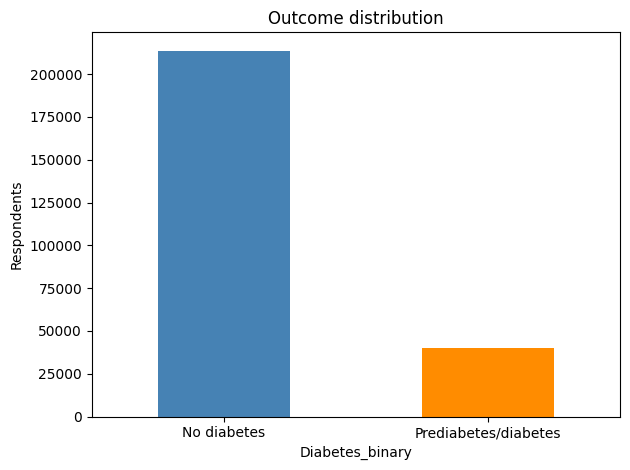

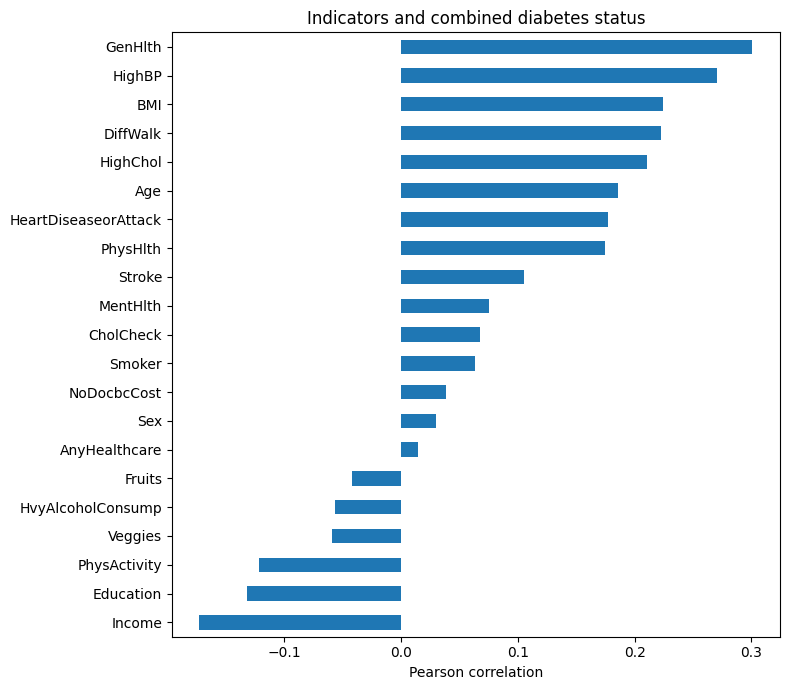

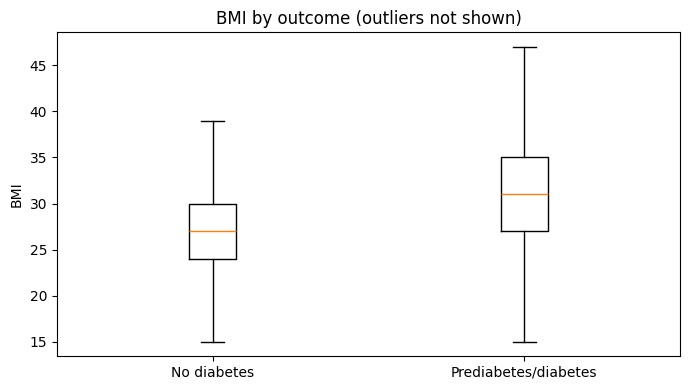

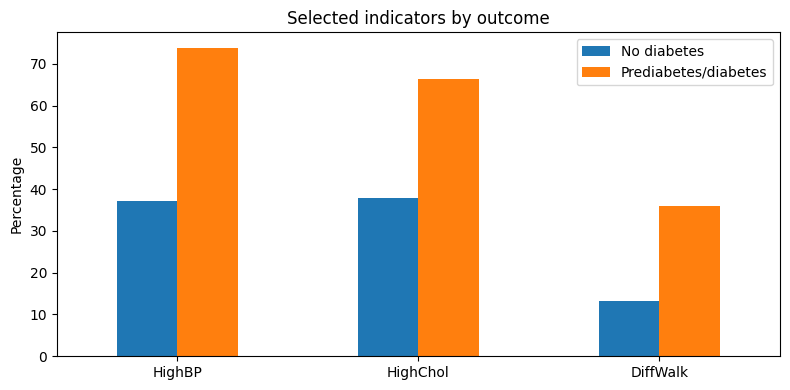

In [6]:
labels = ['No diabetes', 'Prediabetes/diabetes']
def saveplot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=200, bbox_inches='tight')
    plt.show()

# Recreate summary if it is missing from the environment
if 'summary' not in globals():
    summary = y.value_counts().sort_index().rename('count').to_frame()
    summary['percentage'] = summary['count'] / len(y) * 100
    summary.index.name = 'Diabetes_binary'

summary['count'].plot.bar(color=['steelblue', 'darkorange'])
plt.xticks([0, 1], labels, rotation=0)
plt.ylabel('Respondents'); plt.title('Outcome distribution')
saveplot('01_outcome_distribution.png')
corr = X.corrwith(y).sort_values()
corr.to_csv(OUT / 'target_correlations.csv', header=['Pearson_r'])
corr.plot.barh(figsize=(8, 7))
plt.xlabel('Pearson correlation'); plt.title('Indicators and combined diabetes status')
saveplot('02_correlations.png')
plt.figure(figsize=(7, 4))
plt.boxplot([X.loc[y == i, 'BMI'] for i in [0, 1]], tick_labels=labels, showfliers=False)
plt.ylabel('BMI'); plt.title('BMI by outcome (outliers not shown)')
saveplot('03_bmi.png')
X.assign(Outcome=y).groupby('Outcome')['BMI'].agg(['mean','median','std']).to_csv(OUT / 'bmi_summary.csv')
risk = X[['HighBP','HighChol','DiffWalk']].groupby(y).mean().T * 100
risk.columns = labels
risk.plot.bar(figsize=(8, 4))
plt.ylabel('Percentage'); plt.xticks(rotation=0); plt.title('Selected indicators by outcome')
saveplot('04_selected_indicators.png')

## 3. Split and tune models
Scaling is fitted inside each training fold through a Pipeline, so validation-fold information never enters preprocessing. Both models receive the same transformed features. Random Forest tuning took about 11 minutes in the reported Colab run. Do not reduce the data or the grid and still describe the run as the full reported analysis.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def preprocessing():
    return ColumnTransformer([('scale', StandardScaler(), scaled)],
                             remainder='passthrough', verbose_feature_names_out=False)
lr = Pipeline([('preprocess', preprocessing()),
               ('model', LogisticRegression(solver='lbfgs', max_iter=2000,
                                            class_weight='balanced', random_state=SEED))])
rf = Pipeline([('preprocess', preprocessing()),
               ('model', RandomForestClassifier(n_estimators=200,
                        class_weight='balanced', random_state=SEED, n_jobs=1))])
specs = {
    'Logistic Regression': (lr, {'model__C': [0.01, 0.1, 1.0, 10.0]}),
    'Random Forest': (rf, {'model__max_depth': [10, 20],
                          'model__min_samples_leaf': [1, 5]})
}
print('Training:', X_train.shape, 'Test:', X_test.shape)
print('Class counts, training:', y_train.value_counts().sort_index().to_dict())
print('Class counts, test:', y_test.value_counts().sort_index().to_dict())
searches = {}
elapsed = {}
for name, (pipe, grid) in specs.items():
    start = time.time()
    search = GridSearchCV(pipe, grid, scoring='f1', cv=cv, n_jobs=2,
                          pre_dispatch=2, refit=True, verbose=2, error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    elapsed[name] = round((time.time() - start) / 60, 1)
    stem = name.lower().replace(' ', '_')
    pd.DataFrame(search.cv_results_).to_csv(OUT / f'{stem}_cross_validation.csv', index=False)
    print(name, search.best_params_, 'CV F1:', search.best_score_,
          'Elapsed minutes:', elapsed[name])

Training: (202944, 21) Test: (50736, 21)
Class counts, training: {0: 170962, 1: 31982}
Class counts, test: {0: 42741, 1: 7995}
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Logistic Regression {'model__C': 0.01} CV F1: 0.46971494605521313 Elapsed minutes: 0.3
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random Forest {'model__max_depth': 20, 'model__min_samples_leaf': 5} CV F1: 0.4847986062044953 Elapsed minutes: 11.1


## 4. Final test-set evaluation
Use these actual outputs in the report. The test set is used once. Do not adjust the pipeline based on test-set performance.

,Accuracy,Precision,Recall,F1,ROC_AUC,CV_F1
Model,,,,,,
Logistic Regression,0.7307,0.3411,0.7609,0.4711,0.8175,0.4697
Random Forest,0.7778,0.3812,0.6574,0.4826,0.8186,0.4848


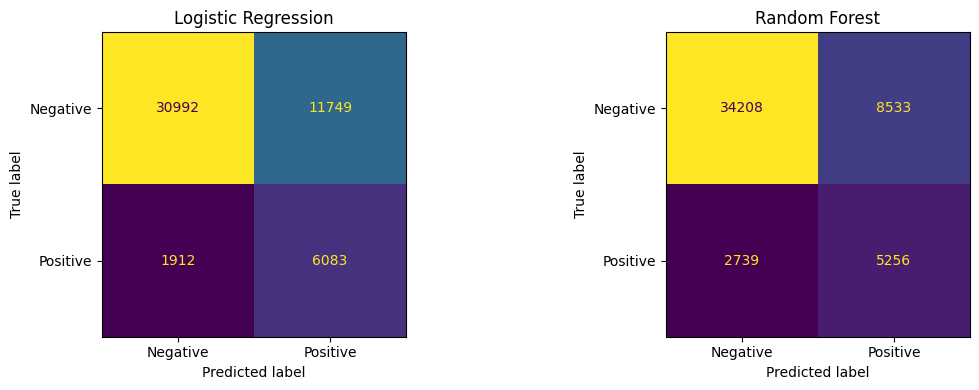

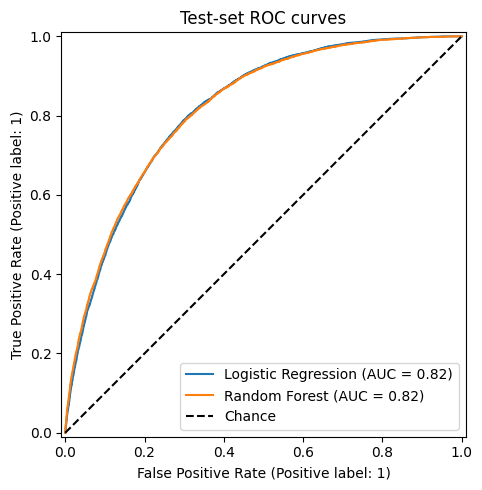

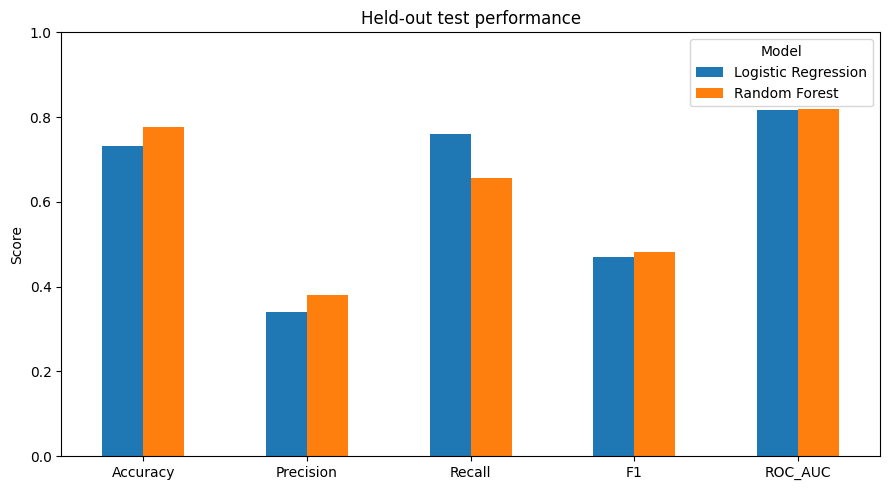

Always-negative baseline accuracy: 0.8424195837275308
Interpret class-specific recall and precision alongside accuracy.


In [9]:
rows = []
fig_cm, axes_cm = plt.subplots(1, 2, figsize=(12, 4))
fig_roc, ax_roc = plt.subplots(figsize=(7, 5))
probabilities, predictions, cms = {}, {}, {}
for i, (name, search) in enumerate(searches.items()):
    model = search.best_estimator_
    prob = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    probabilities[name] = prob
    predictions[name] = pred
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred),
                 'ROC_AUC': roc_auc_score(y_test, prob),
                 'CV_F1': search.best_score_})
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    cms[name] = cm
    stem = name.lower().replace(' ', '_')
    pd.DataFrame(cm, index=['Actual negative','Actual positive'],
                 columns=['Predicted negative','Predicted positive']).to_csv(OUT / f'{stem}_confusion_matrix.csv')
    report = classification_report(y_test, pred, target_names=labels, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(OUT / f'{stem}_classification_report.csv')
    ConfusionMatrixDisplay(cm, display_labels=['Negative','Positive']).plot(ax=axes_cm[i], colorbar=False)
    axes_cm[i].set_title(name)
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax_roc)
metrics = pd.DataFrame(rows).set_index('Model')
display(metrics.round(4))
metrics.to_csv(OUT / 'test_metrics.csv')
# NEW: save predictions so AUC intervals and paired tests can be recomputed later
pd.DataFrame({'y_true': y_test.values,
              'prob_lr': probabilities['Logistic Regression'], 'pred_lr': predictions['Logistic Regression'],
              'prob_rf': probabilities['Random Forest'], 'pred_rf': predictions['Random Forest']}
             ).to_csv(OUT / 'test_predictions.csv', index=False)
fig_cm.tight_layout(); fig_cm.savefig(OUT / '05_confusion_matrices.png', dpi=200)
ax_roc.plot([0, 1], [0, 1], 'k--', label='Chance')
ax_roc.legend(); ax_roc.set_title('Test-set ROC curves')
fig_roc.tight_layout(); fig_roc.savefig(OUT / '06_roc_curves.png', dpi=200)
plt.show()
metrics[['Accuracy','Precision','Recall','F1','ROC_AUC']].T.plot.bar(figsize=(9, 5))
plt.ylim(0, 1); plt.xticks(rotation=0); plt.ylabel('Score')
plt.title('Held-out test performance'); saveplot('07_metric_comparison.png')
print('Always-negative baseline accuracy:', (y_test == 0).mean())
print('Interpret class-specific recall and precision alongside accuracy.')

## 5. Predictor contributions
Run it. It creates Figures 8 and 9 and the coefficient, odds-ratio and importance tables for the **main** target. Coefficients mix scaled and unscaled predictors, so do not rank them against each other as if comparable, and impurity importance can favour predictors with many split points.

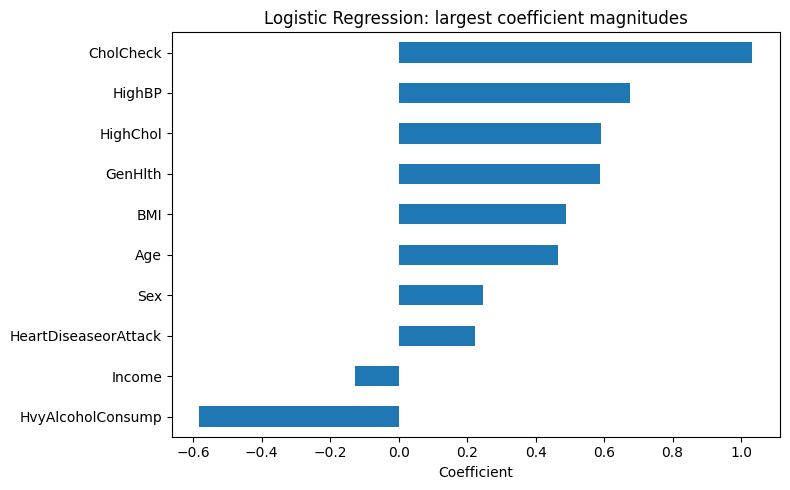

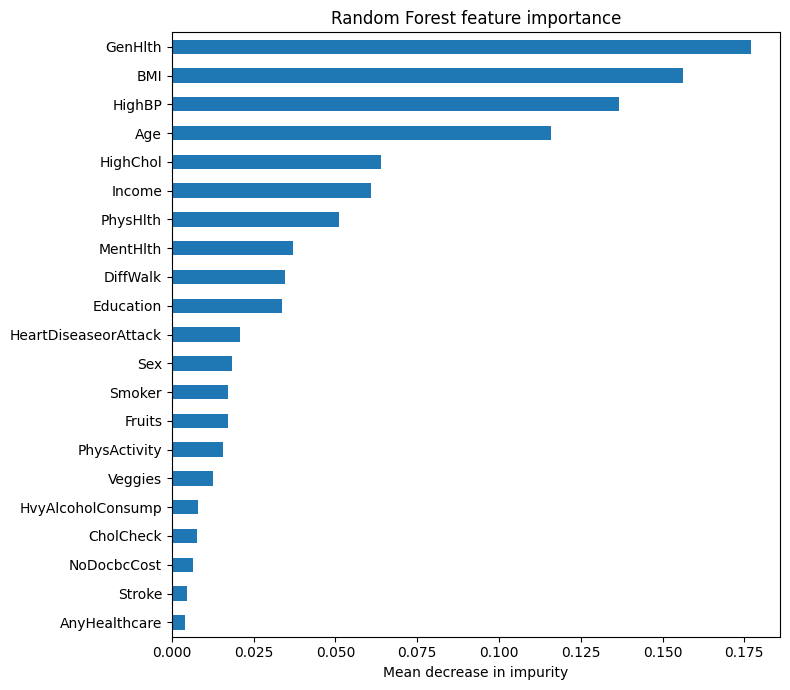

,coefficient,odds_ratio
CholCheck,1.0330,2.8095
HighBP,0.6768,1.9675
HighChol,0.5904,1.8046
GenHlth,0.5885,1.8013
BMI,0.4874,1.6281
Age,0.4651,1.5921
Sex,0.2466,1.2797
HeartDiseaseorAttack,0.2215,1.2479
NoDocbcCost,0.0950,1.0997
Stroke,0.0942,1.0988


,Gini_importance
GenHlth,0.1770
BMI,0.1563
HighBP,0.1366
Age,0.1159
HighChol,0.0640
Income,0.0608
PhysHlth,0.0511
MentHlth,0.0371
DiffWalk,0.0346
Education,0.0336


Coefficient magnitudes use mixed units: standardized numeric/ordinal predictors and unscaled binary predictors.
Do not interpret these rankings as causal effects or directly equate them with forest importance.
Impurity importance can favour predictors with more possible split points.


In [12]:
best_lr = searches['Logistic Regression'].best_estimator_
names_lr = best_lr.named_steps['preprocess'].get_feature_names_out()
coef = pd.Series(best_lr.named_steps['model'].coef_[0], index=names_lr, name='coefficient')
coef.to_csv(OUT / 'logistic_coefficients.csv')
odds = pd.DataFrame({'coefficient': coef, 'odds_ratio': np.exp(coef)}).sort_values('coefficient')
odds.to_csv(OUT / 'logistic_odds_ratios.csv')
coef.loc[coef.abs().nlargest(10).index].sort_values().plot.barh(figsize=(8, 5))
plt.xlabel('Coefficient'); plt.title('Logistic Regression: largest coefficient magnitudes')
saveplot('08_logistic_coefficients.png')
best_rf = searches['Random Forest'].best_estimator_
importance = pd.Series(best_rf.named_steps['model'].feature_importances_,
                       index=best_rf.named_steps['preprocess'].get_feature_names_out(),
                       name='Gini_importance').sort_values()
importance.to_csv(OUT / 'random_forest_importance.csv')
importance.plot.barh(figsize=(8, 7))
plt.xlabel('Mean decrease in impurity'); plt.title('Random Forest feature importance')
saveplot('09_random_forest_importance.png')
display(odds.round(4).sort_values('coefficient', ascending=False).head(10))
display(importance.sort_values(ascending=False).round(4).head(10).to_frame())
print('Coefficient magnitudes use mixed units: standardized numeric/ordinal predictors and unscaled binary predictors.')
print('Do not interpret these rankings as causal effects or directly equate them with forest importance.')
print('Impurity importance can favour predictors with more possible split points.')

## 6. Report-matching section (new)
This section (a) exports every derived number used in the dissertation and (b) compares the key results with the values reported in the dissertation. Each line prints PASS or FAIL. If everything passes, the dissertation tables can be filled directly from the files in the results folder.

In [11]:
# ---- 6a. Derived metrics with 95% bootstrap intervals (multinomial resampling of the confusion matrix) ----
rng = np.random.default_rng(SEED)
derived, boot_ci = {}, {}
for name, cm in cms.items():
    tn, fp, fn, tp = cm.ravel(); n = cm.sum()
    point = {'Accuracy': (tp + tn) / n, 'Precision': tp / (tp + fp), 'Recall': tp / (tp + fn),
             'Specificity': tn / (tn + fp), 'F1': 2 * tp / (2 * tp + fp + fn), 'NPV': tn / (tn + fn)}
    s = rng.multinomial(n, cm.ravel() / n, size=10000)
    TN, FP, FN, TP = s.T
    sim = {'Accuracy': (TP + TN) / n, 'Precision': TP / (TP + FP), 'Recall': TP / (TP + FN),
           'Specificity': TN / (TN + FP), 'F1': 2 * TP / (2 * TP + FP + FN), 'NPV': TN / (TN + FN)}
    boot_ci[name] = {k: (float(point[k]), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
                     for k, v in sim.items()}
    derived[name] = {'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
                     'flagged_positive': int(tp + fp), 'flagged_share': float((tp + fp) / n),
                     'flagged_per_true_case': float((tp + fp) / tp),
                     'missed_share_of_true_cases': float(fn / (fn + tp))}
tab = pd.DataFrame({f'{m}_{k}': {'estimate': v[0], 'ci_low': v[1], 'ci_high': v[2]}
                    for m, d in boot_ci.items() for k, v in d.items()}).T
display(tab.round(4)); tab.to_csv(OUT / 'bootstrap_confidence_intervals.csv')

# ---- 6b. Paired bootstrap on the saved predictions (differences are Random Forest minus Logistic Regression) ----
yt = y_test.values; n_t = len(yt)
pl, pf = predictions['Logistic Regression'], predictions['Random Forest']
ql, qf = probabilities['Logistic Regression'], probabilities['Random Forest']
diffs = []
for b in range(1000):
    idx = rng.integers(0, n_t, n_t)
    diffs.append({'Accuracy': accuracy_score(yt[idx], pf[idx]) - accuracy_score(yt[idx], pl[idx]),
                  'Precision': precision_score(yt[idx], pf[idx], zero_division=0) - precision_score(yt[idx], pl[idx], zero_division=0),
                  'Recall': recall_score(yt[idx], pf[idx]) - recall_score(yt[idx], pl[idx]),
                  'F1': f1_score(yt[idx], pf[idx]) - f1_score(yt[idx], pl[idx]),
                  'ROC_AUC': roc_auc_score(yt[idx], qf[idx]) - roc_auc_score(yt[idx], ql[idx])})
paired = pd.DataFrame({k: [np.percentile([d[k] for d in diffs], q) for q in (2.5, 97.5)] for k in diffs[0]},
                      index=['ci_low', 'ci_high']).T
display(paired.round(4)); paired.to_csv(OUT / 'paired_bootstrap_RF_minus_LR.csv')

# ---- 6c. Error trade-off and break-even cost ratio ----
extra_missed = derived['Random Forest']['FN'] - derived['Logistic Regression']['FN']
false_alarms_avoided = derived['Logistic Regression']['FP'] - derived['Random Forest']['FP']
breakeven = false_alarms_avoided / extra_missed
print(f'RF misses {extra_missed} more true cases but avoids {false_alarms_avoided} false alarms; '
      f'break-even = {breakeven:.2f} false alarms per extra missed case')

# ---- 6d. Duplicate-profile diagnostic: share of test rows whose exact profile also occurs in training ----
train_profiles = set(map(tuple, X_train.values))
overlap = float(np.mean([tuple(r) in train_profiles for r in X_test.values]))
print(f'Test rows with an identical feature profile in the training set: {overlap:.2%}')

# ---- 6e. Macro-F1 and export of everything ----
macro = {}
for name in cms:
    r = pd.read_csv(OUT / f"{name.lower().replace(' ', '_')}_classification_report.csv", index_col=0)
    macro[name] = float(r.loc['macro avg', 'f1-score'])
report_numbers = {'quality': quality, 'best_params': {k: v.best_params_ for k, v in searches.items()},
                  'cv_f1': {k: float(v.best_score_) for k, v in searches.items()},
                  'tuning_minutes': elapsed, 'test_metrics': metrics.round(6).to_dict('index'),
                  'confusion_matrices': {k: v.tolist() for k, v in cms.items()},
                  'derived': derived, 'macro_f1': macro, 'baseline_accuracy': float((y_test == 0).mean()),
                  'breakeven_false_alarms_per_extra_missed_case': float(breakeven),
                  'train_test_profile_overlap': overlap}
(OUT / 'report_numbers.json').write_text(json.dumps(report_numbers, indent=2))
print('Saved report_numbers.json')

,estimate,ci_low,ci_high
Logistic Regression_Accuracy,0.7307,0.7268,0.7346
Logistic Regression_Precision,0.3411,0.3342,0.3481
Logistic Regression_Recall,0.7609,0.7515,0.7702
Logistic Regression_Specificity,0.7251,0.7208,0.7293
Logistic Regression_F1,0.4711,0.4635,0.4786
Logistic Regression_NPV,0.9419,0.9394,0.9444
Random Forest_Accuracy,0.7778,0.7742,0.7815
Random Forest_Precision,0.3812,0.3730,0.3893
Random Forest_Recall,0.6574,0.6468,0.6679
Random Forest_Specificity,0.8004,0.7966,0.8042


,ci_low,ci_high
Accuracy,0.0446,0.0498
Precision,0.0364,0.0437
Recall,-0.1107,-0.0963
F1,0.0071,0.0159
ROC_AUC,-0.0006,0.0029


RF misses 827 more true cases but avoids 3216 false alarms; break-even = 3.89 false alarms per extra missed case
Test rows with an identical feature profile in the training set: 13.62%
Saved report_numbers.json


In [13]:
# ---- 6f. Check the run against the values reported in the dissertation ----
expected = {
    'rows': (quality['rows'], 253680), 'positives': (int(y.sum()), 39977), 'negatives': (int((y == 0).sum()), 213703),
    'duplicate rows': (quality['duplicate_rows_original_columns'], 23899),
    'train size': (len(X_train), 202944), 'test size': (len(X_test), 50736),
    'train positives': (int(y_train.sum()), 31982), 'test positives': (int(y_test.sum()), 7995),
    'LR best C': (searches['Logistic Regression'].best_params_['model__C'], 0.01),
    'RF max_depth': (searches['Random Forest'].best_params_['model__max_depth'], 20),
    'RF min_samples_leaf': (searches['Random Forest'].best_params_['model__min_samples_leaf'], 5),
    'LR CV F1': (searches['Logistic Regression'].best_score_, 0.4697),
    'RF CV F1': (searches['Random Forest'].best_score_, 0.4848),
}
reported = {'Logistic Regression': (0.7307, 0.3411, 0.7609, 0.4711, 0.8175),
            'Random Forest': (0.7778, 0.3812, 0.6574, 0.4826, 0.8186)}
for m, vals in reported.items():
    for k, v in zip(['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC'], vals):
        expected[f'{m} {k}'] = (metrics.loc[m, k], v)
for m, c in {'Logistic Regression': [[30992, 11749], [1912, 6083]],
             'Random Forest': [[34208, 8533], [2739, 5256]]}.items():
    expected[f'{m} confusion matrix'] = (cms[m].tolist(), c)
ok = True
for k, (got, want) in expected.items():
    if isinstance(want, list): good = got == want
    elif isinstance(want, int): good = int(got) == want
    else: good = abs(float(got) - want) < 6e-5
    ok &= bool(good)
    print(('PASS ' if good else 'FAIL ') + f'{k:34s} got={got}  reported={want}')
if ok:
    print('\nALL CHECKS PASSED: this run reproduces the dissertation.')
else:
    print('\nSOME CHECKS FAILED: do not copy numbers into the dissertation until the cause is found.')
    print('Likely causes: wrong CSV (use the three-class file), different library versions (see the first cell), or a changed pipeline.')

PASS rows                               got=253680  reported=253680
PASS positives                          got=39977  reported=39977
PASS negatives                          got=213703  reported=213703
PASS duplicate rows                     got=23899  reported=23899
PASS train size                         got=202944  reported=202944
PASS test size                          got=50736  reported=50736
PASS train positives                    got=31982  reported=31982
PASS test positives                     got=7995  reported=7995
PASS LR best C                          got=0.01  reported=0.01
PASS RF max_depth                       got=20  reported=20
PASS RF min_samples_leaf                got=5  reported=5
PASS LR CV F1                           got=0.46971494605521313  reported=0.4697
PASS RF CV F1                           got=0.4847986062044953  reported=0.4848
PASS Logistic Regression Accuracy       got=0.7307434563229265  reported=0.7307
PASS Logistic Regression Precision      got=0

## 7. Save reproducibility information and download outputs
The ZIP contains generated figures, tables, tuning results, test predictions and environment information. It excludes fitted models. The ZIP is built only if every expected file exists, so the missing-figure problem of the original run cannot recur.

In [15]:
metadata = {'seed': SEED, 'python': platform.python_version(),
            'pandas': pd.__version__, 'numpy': np.__version__, 'sklearn': sklearn.__version__,
            'source_file': csv_path.name, 'features': features, 'scaled_features': scaled,
            'duplicates_retained': True, 'target': 'Diabetes_012 in [1, 2]',
            'cv': '5-fold stratified, shuffle=True, random_state=42',
            'test_fraction': 0.2, 'all_report_checks_passed': bool(ok),
            'best_parameters': {name: search.best_params_ for name, search in searches.items()}}
(OUT / 'run_metadata.json').write_text(json.dumps(metadata, indent=2))
expected_files = ['01_outcome_distribution.png', '02_correlations.png', '03_bmi.png', '04_selected_indicators.png',
                  '05_confusion_matrices.png', '06_roc_curves.png', '07_metric_comparison.png',
                  '08_logistic_coefficients.png', '09_random_forest_importance.png',
                  'logistic_coefficients.csv', 'logistic_odds_ratios.csv', 'random_forest_importance.csv',
                  'test_metrics.csv', 'test_predictions.csv', 'report_numbers.json',
                  'bootstrap_confidence_intervals.csv', 'paired_bootstrap_RF_minus_LR.csv', 'run_metadata.json']
missing = [f for f in expected_files if not (OUT / f).exists()]
if missing:
    raise FileNotFoundError('Cannot build the ZIP. Missing files (run the earlier cells): ' + str(missing))
archive = shutil.make_archive('/content/diabetes_analysis_results', 'zip', OUT)
from google.colab import files
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>